In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve, roc_auc_score)

MODEL_PATH = "../models/baseline_cnn.keras"
IMG_SIZE = 128      # 224 pour MobileNetV2 / ResNet50
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE

val_df = pd.read_csv("../data/val.csv")
test_df = pd.read_csv("../data/test.csv")
for d in (val_df, test_df):
    d["y"] = d["label"].map({"NORMAL": 0, "PNEUMONIA": 1})

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return img, label

def make_eval_ds(df):
    ds = tf.data.Dataset.from_tensor_slices((df["path"].values, df["y"].values.astype("float32")))
    return ds.map(load_image, num_parallel_calls=AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)

model = tf.keras.models.load_model(MODEL_PATH)

# pas de shuffle : l'ordre des prédictions correspond à celui des CSV
p_val = model.predict(make_eval_ds(val_df)).ravel()
p_test = model.predict(make_eval_ds(test_df)).ravel()
y_val, y_test = val_df["y"].values, test_df["y"].values

28/28 ━━━━━━━━━━━━━━━━━━━━ 4s 134ms/step
28/28 ━━━━━━━━━━━━━━━━━━━━ 5s 185ms/step


In [2]:
fpr, tpr, thr = roc_curve(y_val, p_val)
idx = np.where(tpr >= 0.98)[0][0]
threshold = float(thr[idx])
print(f"Seuil choisi sur val : {threshold:.3f}  (recall val = {tpr[idx]:.3f}, faux positifs = {fpr[idx]:.3f})")

Seuil choisi sur val : 0.385  (recall val = 0.981, faux positifs = 0.270)



=== baseline seuil 0.5 (seuil = 0.500) ===
              precision    recall  f1-score   support

      NORMAL      0.919     0.811     0.862       238
   PNEUMONIA      0.933     0.973     0.953       641

    accuracy                          0.929       879
   macro avg      0.926     0.892     0.907       879
weighted avg      0.929     0.929     0.928       879

Spécificité : 0.811 | Faux négatifs : 17 | Faux positifs : 45


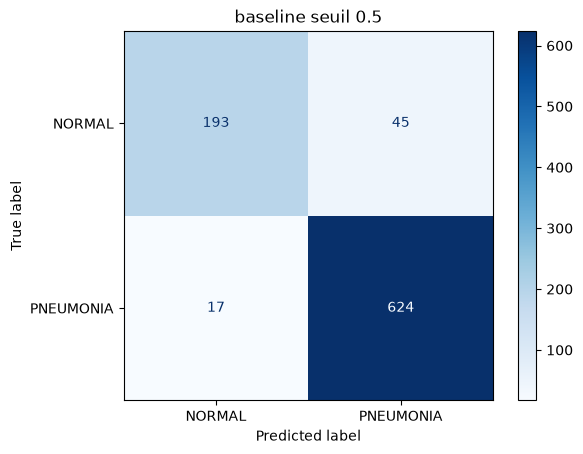


=== baseline seuil choisi (seuil = 0.385) ===
              precision    recall  f1-score   support

      NORMAL      0.936     0.739     0.826       238
   PNEUMONIA      0.910     0.981     0.944       641

    accuracy                          0.916       879
   macro avg      0.923     0.860     0.885       879
weighted avg      0.917     0.916     0.912       879

Spécificité : 0.739 | Faux négatifs : 12 | Faux positifs : 62


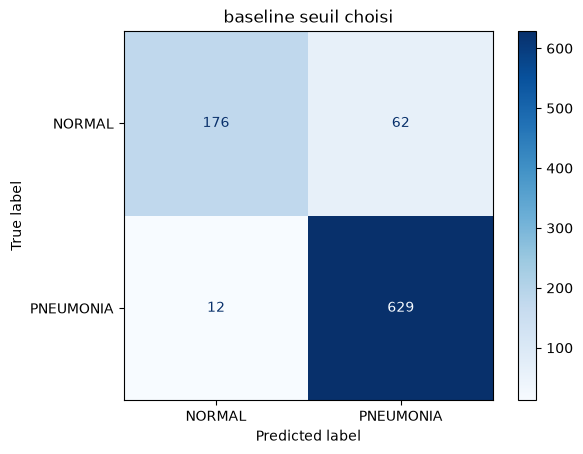

In [3]:
def report(y, p, t, name):
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    print(f"\n=== {name} (seuil = {t:.3f}) ===")
    print(classification_report(y, pred, target_names=["NORMAL", "PNEUMONIA"], digits=3))
    print(f"Spécificité : {tn/(tn+fp):.3f} | Faux négatifs : {fn} | Faux positifs : {fp}")
    ConfusionMatrixDisplay.from_predictions(y, pred, display_labels=["NORMAL", "PNEUMONIA"], cmap="Blues")
    plt.title(name)
    plt.savefig(f"../models/confusion_{name.replace(' ', '_')}.png", dpi=120, bbox_inches="tight")
    plt.show()

report(y_test, p_test, 0.5, "baseline seuil 0.5")
report(y_test, p_test, threshold, "baseline seuil choisi")

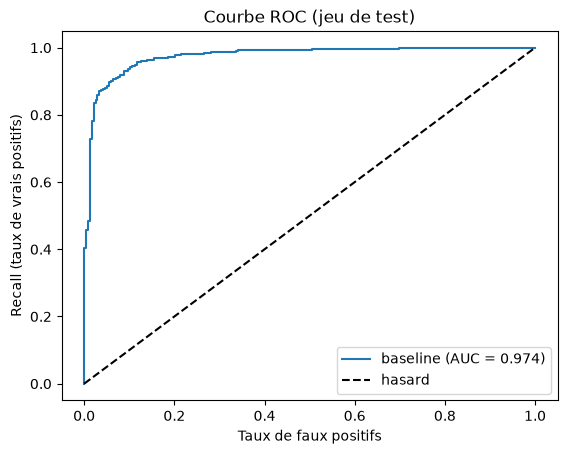

In [4]:
fpr_t, tpr_t, _ = roc_curve(y_test, p_test)
auc = roc_auc_score(y_test, p_test)
plt.plot(fpr_t, tpr_t, label=f"baseline (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="hasard")
plt.xlabel("Taux de faux positifs")
plt.ylabel("Recall (taux de vrais positifs)")
plt.title("Courbe ROC (jeu de test)")
plt.legend()
plt.savefig("../models/roc_baseline.png", dpi=120, bbox_inches="tight")
plt.show()